In [1]:
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
# from mediapipe import solutions
import numpy as np
import cv2
import pandas as pd
import math
import os
import json
from sklearn.metrics import confusion_matrix, classification_report

d:\Coding\Projects\hand gesture recognition\.venv\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [ ]:
cwd = os.getcwd()
base_data_path = os.path.join(cwd, "asl citizen data", "ASL_Citizen")
videos_path = os.path.join(base_data_path, "videos")
splits_path = os.path.join(base_data_path, "splits")

In [ ]:
train = pd.read_csv(os.path.join(splits_path, "train.csv"))
test = pd.read_csv(os.path.join(splits_path, "test.csv"))
val = pd.read_csv(os.path.join(splits_path, "val.csv"))

In [ ]:
train.rename(columns={"Video file": "path", "Participant ID": "participant", "Gloss": "gloss", "ASL-LEX Code": "code"}, inplace=True)
test.rename(columns={"Video file": "path", "Participant ID": "participant", "Gloss": "gloss", "ASL-LEX Code": "code"}, inplace=True)
val.rename(columns={"Video file": "path", "Participant ID": "participant", "Gloss": "gloss", "ASL-LEX Code": "code"}, inplace=True)
train.head()

## Deprecated generator

The inline generator previously stored absolute landmark positions in relative-motion history and passed BGR frames to MediaPipe as RGB. It has been retired. Use the shared `DataGeneration` workflow in the next cell.


In [ ]:
# Generate corrected raw landmark data for every split.
# This is expensive and only needs to run when rebuilding the dataset.
from data_generation import DataGeneration

data_gen = DataGeneration(videos_path)

print("Gathering training data...")
data_gen.generate_from_dataset(train, "train", limit_count=False)
print("Gathering testing data...")
data_gen.generate_from_dataset(test, "test", limit_count=False)
print("Gathering validation data...")
data_gen.generate_from_dataset(val, "val", limit_count=False)


In [7]:
# DATA CLEANING. SHOULD ONLY BE RUN WHEN GENERATING NEW DATA

raw_gesture_data_folder = os.path.join(cwd, "asl_citizen_gesture_data/raw_data")
raw_test = os.path.join(raw_gesture_data_folder, "test")
raw_train = os.path.join(raw_gesture_data_folder, "train")
raw_val = os.path.join(raw_gesture_data_folder, "val")


def frame_lengths(raw_data_path):
    lengths = []
    for filename in sorted(os.listdir(raw_data_path)):
        if not filename.lower().endswith(".csv"):
            continue
        df = pd.read_csv(os.path.join(raw_data_path, filename))
        if not df.empty:
            lengths.append(len(df))
    return lengths


def generate(raw_data_path, main_csv: pd.DataFrame, out_path):
    """Write exact-length gestures; do not pad or truncate samples."""
    cleaned = []
    skipped_empty = []
    skipped_unlabelled = []

    for filename in sorted(os.listdir(raw_data_path)):
        if not filename.lower().endswith(".csv"):
            continue

        file_path = os.path.join(raw_data_path, filename)
        df = pd.read_csv(file_path)
        if df.empty:
            skipped_empty.append(filename)
            continue

        clip_name = os.path.splitext(filename)[0]
        match = main_csv.loc[main_csv["path"] == clip_name, "gloss"]
        if match.empty:
            skipped_unlabelled.append(filename)
            continue

        cleaned.append({
            "word": match.iloc[0],
            "data": [df.to_numpy(dtype=np.float32).tolist()],
        })

    with open(out_path, "w") as destination:
        json.dump(cleaned, destination)

    lengths = [len(sample["data"][0]) for sample in cleaned]
    print(
        f"{os.path.basename(raw_data_path)}: {len(cleaned)} gestures, "
        f"length {min(lengths)}-{max(lengths)} frames, "
        f"{len(skipped_empty)} empty and {len(skipped_unlabelled)} unlabelled skipped"
    )


generate(raw_train, train, "asl_citizen_gesture_data/cleaned_train_data.json")
generate(raw_test, test, "asl_citizen_gesture_data/cleaned_test_data.json")
generate(raw_val, val, "asl_citizen_gesture_data/cleaned_val_data.json")


train: 199 gestures, length 10-312 frames, 0 empty and 0 unlabelled skipped
test: 155 gestures, length 8-83 frames, 0 empty and 0 unlabelled skipped
val: 47 gestures, length 19-63 frames, 0 empty and 0 unlabelled skipped


The cleaned JSON files now contain lists of exact-length gestures directly. The former dictionary-to-list conversion step was removed because it was only needed by the old fixed-length cleaning pipeline.


In [8]:
import torch
from torch.utils.data import DataLoader

from gesture_model import (
    GestureClassifier,
    GestureDataset,
    GestureModelConfig,
    collate_gesture_batch,
    evaluate_model,
    load_gesture_checkpoint,
    save_gesture_checkpoint,
    select_device,
    train_gesture_model,
)

device = select_device()
print(f"PyTorch: {torch.__version__}")
print(f"Training device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


PyTorch: 2.13.0+cu130
Training device: cuda
GPU: NVIDIA GeForce RTX 5070


In [9]:
train_data = json.load(open("asl_citizen_gesture_data/cleaned_train_data.json"))
test_data = json.load(open("asl_citizen_gesture_data/cleaned_test_data.json"))
val_data = json.load(open("asl_citizen_gesture_data/cleaned_val_data.json"))

combined_data = train_data + test_data + val_data
unique_words = sorted({sample["word"] for sample in combined_data})
numbered_unique_words = {word: index for index, word in enumerate(unique_words)}
word_to_number = {index: word for word, index in numbered_unique_words.items()}


def load_split(samples):
    features = [
        np.asarray(sample["data"][0], dtype=np.float32)
        for sample in samples
    ]
    labels = np.asarray(
        [numbered_unique_words[sample["word"]] for sample in samples],
        dtype=np.int64,
    )
    return features, labels


train_X, train_y = load_split(train_data)
test_X, test_Y = load_split(test_data)
val_X, val_Y = load_split(val_data)

print(
    "Raw train gestures:", len(train_X),
    "length range:", min(map(len, train_X)), "-", max(map(len, train_X)),
    "features per frame:", train_X[0].shape[1],
)
print(numbered_unique_words)


Raw train gestures: 199 length range: 10 - 312 features per frame: 255
{'CLOSEEYES': 0, 'EYES': 1, 'HELLO': 2, 'MORE': 3, 'NO': 4, 'ORANGEEYES': 5, 'PIANO': 6, 'PLEASE': 7, 'RHINO3': 8, 'SOPHOMORE': 9, 'THANKYOU': 10, 'TWOMORE': 11, 'YES': 12}


In [10]:
from gesture_preprocessing import add_velocity


def augment_split(gestures):
    return [add_velocity(gesture[np.newaxis, ...])[0] for gesture in gestures]


train_X = augment_split(train_X)
val_X = augment_split(val_X)
test_X = augment_split(test_X)
print(
    "Augmented train gestures:", len(train_X),
    "length range:", min(map(len, train_X)), "-", max(map(len, train_X)),
    "features per frame:", train_X[0].shape[1],
)


Augmented train gestures: 199 length range: 10 - 312 features per frame: 510


In [11]:
# Save one augmented example for live/offline parity comparisons.
gesture_example_index = int(np.argwhere(val_Y == 2)[0, 0])
example = val_X[gesture_example_index]
example_with_label = np.insert(example, 0, val_Y[gesture_example_index])
pd.DataFrame(example_with_label.reshape(1, -1)).to_csv(
    "asl_citizen_gesture_data/example_for_comparison.csv",
    index=False,
)


In [12]:
parameters = {
    "word_to_number": word_to_number,
    "numbered_unique_words": numbered_unique_words,
    "data_per_frame": int(train_X[0].shape[1]),
    "feature_schema_version": 2,
    "motion_uses_timestamps": True,
    "hand_order": ["right", "left"],
    "framework": "pytorch",
    "model_file": "hand_gesture_modelv10.pt",
    "variable_length": True,
    "max_live_frames": None,
}

with open("parameters.json", "w") as file:
    json.dump(parameters, file, indent=2)


In [13]:
pin_memory = device.type == "cuda"
batch_size = 32
loader_options = {
    "batch_size": batch_size,
    "num_workers": 0,
    "pin_memory": pin_memory,
    "collate_fn": collate_gesture_batch,
}

train_loader = DataLoader(
    GestureDataset(train_X, train_y),
    shuffle=True,
    **loader_options,
)
val_loader = DataLoader(
    GestureDataset(val_X, val_Y),
    shuffle=False,
    **loader_options,
)
test_loader = DataLoader(
    GestureDataset(test_X, test_Y),
    shuffle=False,
    **loader_options,
)

model_config = GestureModelConfig(
    input_size=int(train_X[0].shape[1]),
    num_classes=len(numbered_unique_words),
)
model = GestureClassifier(model_config).to(device)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

history = train_gesture_model(
    model,
    train_loader,
    val_loader,
    device=device,
    epochs=150,
    patience=15,
    learning_rate=0.001,
)


Trainable parameters: 929,677
Epoch 001: loss=2.4971, accuracy=0.156, val_loss=2.5123, val_accuracy=0.064
Epoch 002: loss=2.2300, accuracy=0.286, val_loss=2.2665, val_accuracy=0.383
Epoch 003: loss=1.9159, accuracy=0.417, val_loss=2.5522, val_accuracy=0.191
Epoch 004: loss=1.6303, accuracy=0.543, val_loss=1.6213, val_accuracy=0.553
Epoch 005: loss=1.3743, accuracy=0.588, val_loss=1.4583, val_accuracy=0.532
Epoch 006: loss=1.1245, accuracy=0.754, val_loss=1.1579, val_accuracy=0.660
Epoch 007: loss=0.8971, accuracy=0.799, val_loss=0.7874, val_accuracy=0.851
Epoch 008: loss=0.7051, accuracy=0.899, val_loss=0.5887, val_accuracy=0.915
Epoch 009: loss=0.5486, accuracy=0.905, val_loss=0.4394, val_accuracy=0.915
Epoch 010: loss=0.4213, accuracy=0.945, val_loss=0.3387, val_accuracy=0.936
Epoch 011: loss=0.3153, accuracy=0.965, val_loss=0.3347, val_accuracy=0.936
Epoch 012: loss=0.2393, accuracy=0.970, val_loss=0.3251, val_accuracy=0.915
Epoch 013: loss=0.1743, accuracy=0.990, val_loss=0.2315, v

## Deprecated TensorFlow experiment

This experiment was removed from the active notebook. The TensorFlow version is preserved in `detect_gestures_tensorflow.ipynb`.


## Deprecated alternate TensorFlow model

This experiment was removed from the active notebook. The TensorFlow version is preserved in `detect_gestures_tensorflow.ipynb`.


## Deprecated v1-v6 training code

This experiment was removed from the active notebook. The TensorFlow version is preserved in `detect_gestures_tensorflow.ipynb`.


In [14]:
test_loss, test_accuracy, test_predictions, test_labels = evaluate_model(
    model, test_loader, device
)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.3%}")


Test loss: 0.4219
Test accuracy: 89.032%


In [15]:
example_index = int(np.argwhere(val_Y == 4)[0, 0])
example_tensor = torch.from_numpy(val_X[example_index][np.newaxis, ...]).to(device)

model.eval()
with torch.inference_mode():
    probabilities = torch.softmax(model(example_tensor), dim=1)[0].cpu().numpy()

print("Expected:", word_to_number[int(val_Y[example_index])])
print("Predicted:", word_to_number[int(np.argmax(probabilities))])
print(probabilities)


Expected: NO
Predicted: NO
[7.7922468e-06 8.3891187e-05 1.0475913e-03 6.3855873e-07 9.9828029e-01
 6.7569374e-05 1.8117447e-05 1.1495449e-06 2.5116465e-06 1.4604012e-05
 1.0440870e-05 6.7164651e-06 4.5866048e-04]


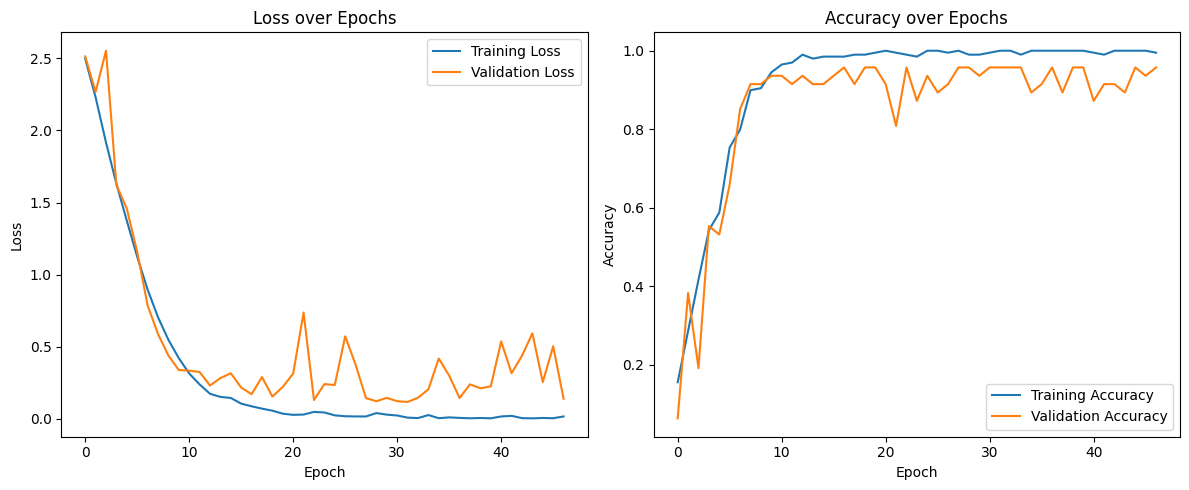

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history["loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.title("Loss over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["accuracy"], label="Training Accuracy")
plt.plot(history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


In [17]:
version = 10
_, best_validation_accuracy, _, _ = evaluate_model(
    model, val_loader, device
)
checkpoint_metadata = {
    "version": version,
    "parameters": parameters,
    "validation_accuracy": best_validation_accuracy,
}

save_gesture_checkpoint(
    f"models/hand_gesture_modelv{version}.pt", model, checkpoint_metadata
)
save_gesture_checkpoint(
    f"website/models/hand_gesture_modelv{version}.pt", model, checkpoint_metadata
)

# Activate v10 only after both checkpoint saves succeed.
with open("website/parameters.json", "w") as destination:
    json.dump(parameters, destination, indent=2)


In [18]:
for split_name, gestures in (
    ("train", train_X),
    ("validation", val_X),
    ("test", test_X),
):
    print(
        f"{split_name}: {len(gestures)} gestures, "
        f"length {min(map(len, gestures))}-{max(map(len, gestures))} frames"
    )
print("The model has no global frame-count contract.")


train: 199 gestures, length 10-312 frames
validation: 47 gestures, length 19-63 frames
test: 155 gestures, length 8-83 frames
The model has no global frame-count contract.


In [19]:
deployed_model, checkpoint_metadata = load_gesture_checkpoint(
    "models/hand_gesture_modelv10.pt", device
)
test_loss, test_accuracy, predictions, labels = evaluate_model(
    deployed_model, test_loader, device
)

print(f"Checkpoint test accuracy: {test_accuracy:.3%}")
print(
    classification_report(
        labels,
        predictions,
        target_names=[word_to_number[i] for i in range(len(word_to_number))],
        zero_division=0,
    )
)
print(confusion_matrix(labels, predictions))


Checkpoint test accuracy: 89.032%
              precision    recall  f1-score   support

   CLOSEEYES       1.00      0.83      0.91        12
        EYES       0.88      0.64      0.74        11
       HELLO       0.93      0.93      0.93        14
        MORE       0.92      1.00      0.96        12
          NO       0.82      0.82      0.82        11
  ORANGEEYES       0.75      1.00      0.86        12
       PIANO       1.00      0.92      0.96        13
      PLEASE       1.00      0.92      0.96        13
      RHINO3       0.85      1.00      0.92        11
   SOPHOMORE       0.92      0.92      0.92        12
    THANKYOU       0.91      0.83      0.87        12
     TWOMORE       0.79      0.92      0.85        12
         YES       0.89      0.80      0.84        10

    accuracy                           0.89       155
   macro avg       0.90      0.89      0.89       155
weighted avg       0.90      0.89      0.89       155

[[10  0  0  0  0  2  0  0  0  0  0  0  0]
 [ 